In [1]:
import pandas as pd

In [2]:
import pandas as pd

df = pd.read_excel("UNSW_NB15_training-set.xlsx")

print("Dataset Shape:", df.shape)

Dataset Shape: (175341, 45)


In [3]:
df.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  str    
 3   service            175341 non-null  str    
 4   state              175341 non-null  str    
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  sinpkt       

In [5]:
df.isnull().sum()

id                   0
dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm           0
ct_srv_dst           0
is_sm_ips_ports      0
attack_cat 

In [6]:
print(df['label'].value_counts())

label
1    119341
0     56000
Name: count, dtype: int64


In [7]:
print(df['attack_cat'].value_counts())

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


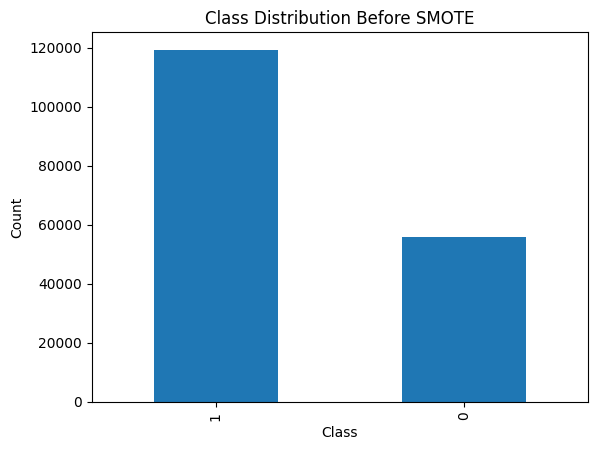

In [8]:
import matplotlib.pyplot as plt

df['label'].value_counts().plot(
    kind='bar'
)

plt.title("Class Distribution Before SMOTE")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [9]:
categorical_columns = df.select_dtypes(include='object').columns

print(categorical_columns)

Index(['proto', 'service', 'state', 'attack_cat'], dtype='str')


C:\Users\Remya R Nair\AppData\Local\Temp\ipykernel_26572\3910604682.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include='object').columns


In [10]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

from imblearn.over_sampling import SMOTE

import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
df = pd.read_excel("UNSW_NB15_training-set.xlsx")

print(df.shape)

(175341, 45)


In [12]:
print(df['attack_cat'].value_counts())

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [13]:
categorical_cols = df.select_dtypes(include='object').columns

print(categorical_cols)

Index(['proto', 'service', 'state', 'attack_cat'], dtype='str')


C:\Users\Remya R Nair\AppData\Local\Temp\ipykernel_26572\1616883611.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include='object').columns


In [14]:
feature_encoders = {}

for col in categorical_cols:

    if col != 'attack_cat':

        le = LabelEncoder()

        df[col] = le.fit_transform(df[col].astype(str))

        feature_encoders[col] = le

In [15]:
attack_encoder = LabelEncoder()

y = attack_encoder.fit_transform(df['attack_cat'])

In [16]:
X = df.drop(['attack_cat', 'label'], axis=1)

In [17]:
X = df.drop(['attack_cat'], axis=1)

In [18]:
print(pd.Series(y).value_counts())

6    56000
5    40000
3    33393
4    18184
2    12264
7    10491
0     2000
1     1746
8     1133
9      130
Name: count, dtype: int64


In [19]:
smote = SMOTE(random_state=42)

X_balanced, y_balanced = smote.fit_resample(X, y)

In [20]:
print(pd.Series(y_balanced).value_counts())

6    56000
1    56000
0    56000
4    56000
8    56000
7    56000
3    56000
2    56000
9    56000
5    56000
Name: count, dtype: int64


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X_balanced,
    y_balanced,
    test_size=0.2,
    random_state=42,
    stratify=y_balanced
)

In [22]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [23]:
models = {

    "Decision Tree":
        DecisionTreeClassifier(),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ),

    "KNN":
        KNeighborsClassifier(),

    "SVM":
        SVC()
}

In [ ]:
results = []

for name, model in models.items():

    print("\n" + "="*60)

    print(name)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)

    results.append([name, acc])

    print("Accuracy =", acc)

    print(classification_report(y_test, y_pred))


Decision Tree
Accuracy = 0.8715446428571428
              precision    recall  f1-score   support

           0       0.83      0.83      0.83     11200
           1       0.83      0.83      0.83     11200
           2       0.63      0.64      0.64     11200
           3       0.70      0.70      0.70     11200
           4       0.91      0.89      0.90     11200
           5       0.99      0.99      0.99     11200
           6       1.00      1.00      1.00     11200
           7       0.86      0.85      0.86     11200
           8       0.97      0.98      0.98     11200
           9       0.99      1.00      1.00     11200

    accuracy                           0.87    112000
   macro avg       0.87      0.87      0.87    112000
weighted avg       0.87      0.87      0.87    112000


Random Forest
Accuracy = 0.8885714285714286
              precision    recall  f1-score   support

           0       0.83      0.87      0.85     11200
           1       0.82      0.88      0.8

In [1]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

from imblearn.over_sampling import SMOTE

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel("UNSW_NB15_training-set.xlsx")

print(df.shape)

(175341, 45)


In [3]:
print(df['attack_cat'].value_counts())
categorical_cols = df.select_dtypes(include='object').columns

print(categorical_cols)
feature_encoders = {}

for col in categorical_cols:

    if col != 'attack_cat':

        le = LabelEncoder()

        df[col] = le.fit_transform(df[col].astype(str))

        feature_encoders[col] = le
        attack_encoder = LabelEncoder()

y = attack_encoder.fit_transform(df['attack_cat'])
X = df.drop(['attack_cat'], axis=1)
print(pd.Series(y).value_counts())
smote = SMOTE(random_state=42)

X_balanced, y_balanced = smote.fit_resample(X, y)
print(pd.Series(y_balanced).value_counts())


attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64
Index(['proto', 'service', 'state', 'attack_cat'], dtype='str')
6    56000
5    40000
3    33393
4    18184
2    12264
7    10491
0     2000
1     1746
8     1133
9      130
Name: count, dtype: int64


C:\Users\Remya R Nair\AppData\Local\Temp\ipykernel_10628\3298257233.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include='object').columns


6    56000
1    56000
0    56000
4    56000
8    56000
7    56000
3    56000
2    56000
9    56000
5    56000
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_balanced,
    y_balanced,
    test_size=0.2,
    random_state=42,
    stratify=y_balanced
)

In [5]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [6]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": KNeighborsClassifier()
}

In [7]:
results = []

for name, model in models.items():

    print("\n" + "="*50)
    print(name)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)

    results.append([name, acc])

    print("Accuracy:", round(acc,4))

results_df = pd.DataFrame(
    results,
    columns=['Model', 'Accuracy']
)

print(results_df)


Decision Tree
Accuracy: 0.8714

Random Forest
Accuracy: 0.8886

KNN
Accuracy: 0.8173
           Model  Accuracy
0  Decision Tree  0.871411
1  Random Forest  0.888571
2            KNN  0.817295


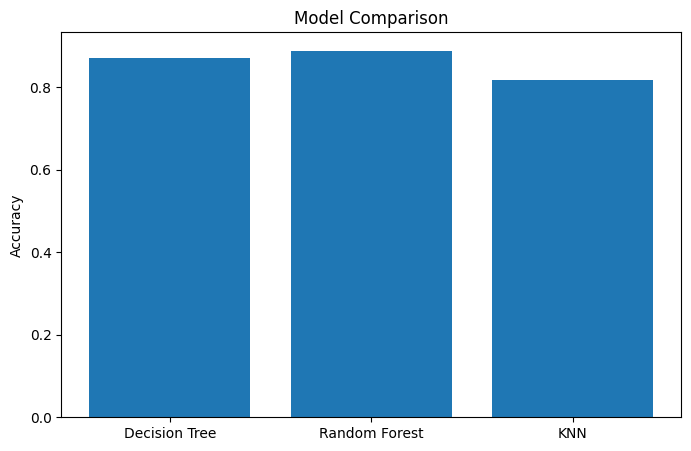

In [8]:
plt.figure(figsize=(8,5))

plt.bar(
    results_df['Model'],
    results_df['Accuracy']
)

plt.title("Model Comparison")

plt.ylabel("Accuracy")

plt.show()

In [9]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

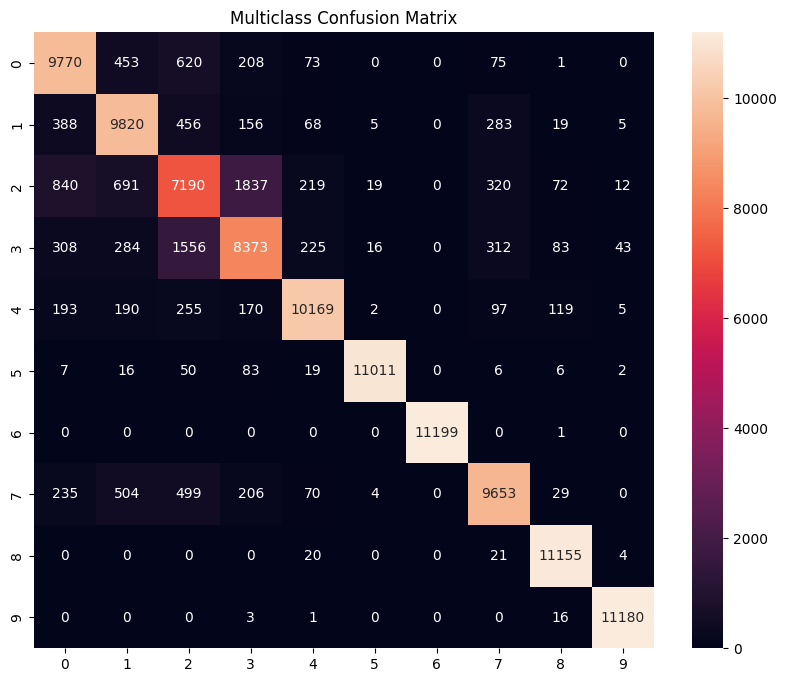

In [10]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d'
)

plt.title("Multiclass Confusion Matrix")

plt.show()

In [11]:
predicted_attack_names = attack_encoder.inverse_transform(y_pred)

print(predicted_attack_names[:20])

['Worms' 'Backdoor' 'Backdoor' 'Backdoor' 'Worms' 'Backdoor' 'Normal'
 'Fuzzers' 'Backdoor' 'Exploits' 'Generic' 'Shellcode' 'DoS' 'Exploits'
 'Normal' 'Worms' 'Fuzzers' 'Normal' 'Backdoor' 'Normal']


In [12]:
importance = rf.feature_importances_

feature_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

feature_df = feature_df.sort_values(
    by='Importance',
    ascending=False
)

print(feature_df.head(15))

             Feature  Importance
0                 id    0.178822
7             sbytes    0.083020
27             smean    0.062036
36    ct_dst_src_ltm    0.051279
2              proto    0.048614
43             label    0.047164
10              sttl    0.044257
41        ct_srv_dst    0.043816
3            service    0.042944
8             dbytes    0.028705
31        ct_srv_src    0.025192
40        ct_src_ltm    0.021637
12             sload    0.021038
35  ct_dst_sport_ltm    0.020710
28             dmean    0.020272


Training Shape : (175341, 45)
Testing Shape  : (82332, 45)

Attack Category Distribution (Training Data)
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

Attack Classes:
['Analysis' 'Backdoor' 'DoS' 'Exploits' 'Fuzzers' 'Generic' 'Normal'
 'Reconnaissance' 'Shellcode' 'Worms']

Before SMOTE:
6    56000
5    40000
3    33393
4    18184
2    12264
7    10491
0     2000
1     1746
8     1133
9      130
Name: count, dtype: int64

After SMOTE:
Analysis : 56000
Backdoor : 56000
DoS : 56000
Exploits : 56000
Fuzzers : 56000
Generic : 56000
Normal : 56000
Reconnaissance : 56000
Shellcode : 56000
Worms : 56000


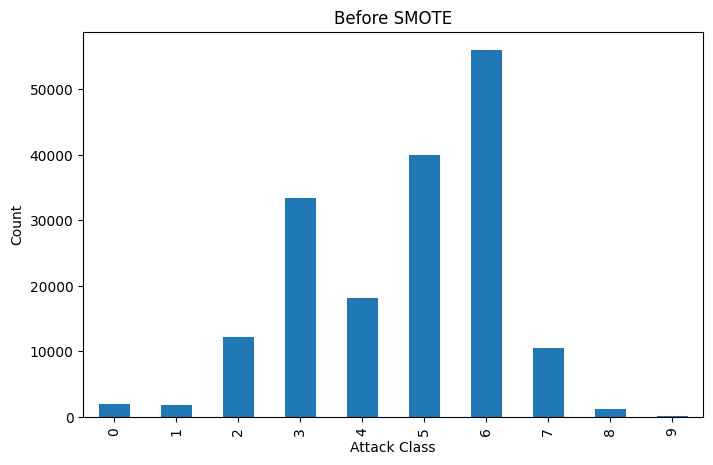

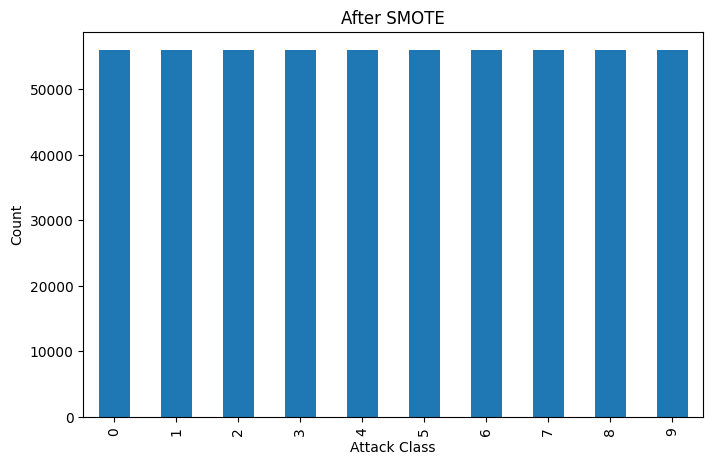


Decision Tree
Accuracy: 0.4311

Random Forest
Accuracy: 0.6459

KNN
Accuracy: 0.5332

Model Comparison
           Model  Accuracy
0  Decision Tree  0.431096
1  Random Forest  0.645934
2            KNN  0.533158


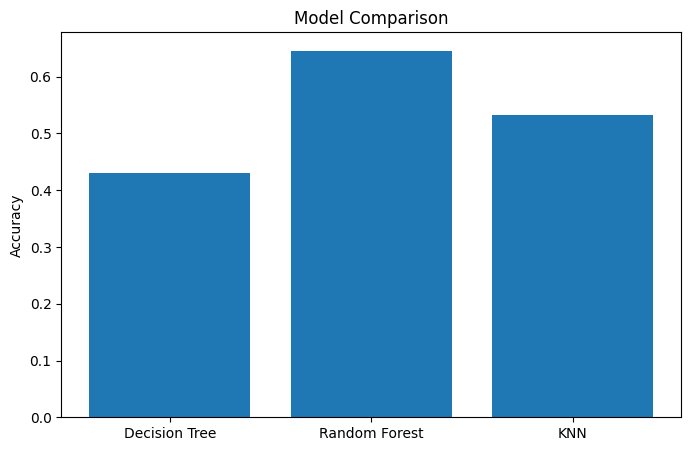


Random Forest Classification Report

              precision    recall  f1-score   support

           0       0.04      0.20      0.07       677
           1       0.02      0.14      0.04       583
           2       0.27      0.10      0.14      4089
           3       0.79      0.50      0.61     11132
           4       0.18      0.39      0.25      6062
           5       1.00      0.96      0.98     18871
           6       0.76      0.67      0.71     37000
           7       0.88      0.48      0.62      3496
           8       0.14      0.44      0.21       378
           9       0.38      0.39      0.38        44

    accuracy                           0.65     82332
   macro avg       0.45      0.43      0.40     82332
weighted avg       0.74      0.65      0.68     82332



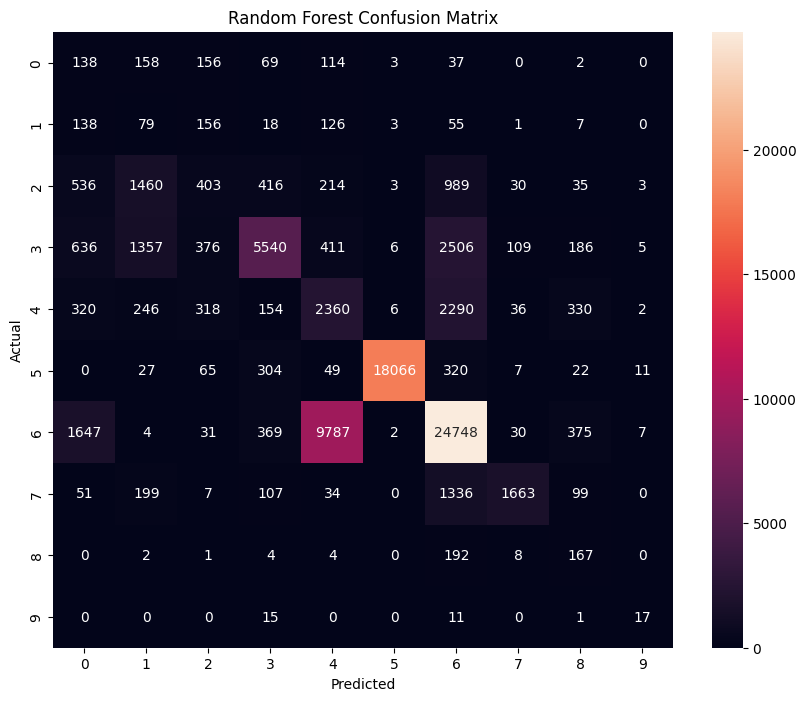


Top 15 Important Features
             Feature  Importance
0                 id    0.199194
7             sbytes    0.087584
27             smean    0.060356
36    ct_dst_src_ltm    0.053570
3            service    0.046003
2              proto    0.045365
41        ct_srv_dst    0.045184
10              sttl    0.042186
8             dbytes    0.030703
31        ct_srv_src    0.029975
12             sload    0.023491
28             dmean    0.022286
40        ct_src_ltm    0.021488
34  ct_src_dport_ltm    0.019151
9               rate    0.018725

Random Test Sample Predictions:

   Actual Attack Predicted Attack
0         Normal           Normal
1        Generic          Generic
2        Generic          Generic
3         Normal           Normal
4       Exploits         Exploits
5        Generic          Generic
6         Normal           Normal
7       Exploits         Exploits
8         Normal        Shellcode
9       Exploits         Analysis
10       Generic          Generic
11 

In [23]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from imblearn.over_sampling import SMOTE

import matplotlib.pyplot as plt
import seaborn as sns

# =====================================================
# LOAD DATASETS
# =====================================================

train_df = pd.read_excel("UNSW_NB15_training-set.xlsx")
test_df = pd.read_excel("UNSW_NB15_testing-set.xlsx")

print("Training Shape :", train_df.shape)
print("Testing Shape  :", test_df.shape)

# =====================================================
# CLASS DISTRIBUTION BEFORE SMOTE
# =====================================================

print("\nAttack Category Distribution (Training Data)")
print(train_df['attack_cat'].value_counts())

# =====================================================
# ENCODE CATEGORICAL FEATURES
# =====================================================

categorical_cols = ['proto', 'service', 'state']

feature_encoders = {}

for col in categorical_cols:

    le = LabelEncoder()

    combined = pd.concat(
        [train_df[col], test_df[col]],
        axis=0
    ).astype(str)

    le.fit(combined)

    train_df[col] = le.transform(
        train_df[col].astype(str)
    )

    test_df[col] = le.transform(
        test_df[col].astype(str)
    )

    feature_encoders[col] = le

# =====================================================
# ENCODE TARGET VARIABLE
# =====================================================

attack_encoder = LabelEncoder()

combined_attack = pd.concat(
    [train_df['attack_cat'],
     test_df['attack_cat']],
    axis=0
)

attack_encoder.fit(combined_attack)

y_train = attack_encoder.transform(
    train_df['attack_cat']
)

y_test = attack_encoder.transform(
    test_df['attack_cat']
)

print("\nAttack Classes:")
print(attack_encoder.classes_)

# =====================================================
# FEATURES
# =====================================================

X_train = train_df.drop(
    ['attack_cat', 'label'],
    axis=1
)

X_test = test_df.drop(
    ['attack_cat', 'label'],
    axis=1
)

# =====================================================
# APPLY SMOTE ONLY TO TRAINING SET
# =====================================================

print("\nBefore SMOTE:")
print(pd.Series(y_train).value_counts())

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train,
    y_train
)

print("\nAfter SMOTE:")
counts = pd.Series(y_train_balanced).value_counts().sort_index()

for i, count in counts.items():
    print(attack_encoder.classes_[i], ":", count)

# =====================================================
# VISUALIZATION
# =====================================================

plt.figure(figsize=(8,5))

pd.Series(y_train).value_counts().sort_index().plot(
    kind='bar'
)

plt.title("Before SMOTE")
plt.xlabel("Attack Class")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8,5))

pd.Series(y_train_balanced).value_counts().sort_index().plot(
    kind='bar'
)

plt.title("After SMOTE")
plt.xlabel("Attack Class")
plt.ylabel("Count")
plt.show()

# =====================================================
# FEATURE SCALING
# =====================================================

scaler = StandardScaler()

X_train_balanced = scaler.fit_transform(
    X_train_balanced
)

X_test = scaler.transform(
    X_test
)

# =====================================================
# MODELS
# =====================================================

models = {

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ),

    "KNN":
        KNeighborsClassifier()
}

# =====================================================
# TRAIN & EVALUATE
# =====================================================

results = []

for name, model in models.items():

    print("\n" + "="*60)
    print(name)

    model.fit(
        X_train_balanced,
        y_train_balanced
    )

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    results.append(
        [name, accuracy]
    )

    print(
        "Accuracy:",
        round(accuracy,4)
    )

# =====================================================
# MODEL COMPARISON
# =====================================================

results_df = pd.DataFrame(
    results,
    columns=[
        'Model',
        'Accuracy'
    ]
)

print("\nModel Comparison")
print(results_df)

# =====================================================
# ACCURACY GRAPH
# =====================================================

plt.figure(figsize=(8,5))

plt.bar(
    results_df['Model'],
    results_df['Accuracy']
)

plt.title(
    "Model Comparison"
)

plt.ylabel(
    "Accuracy"
)

plt.show()

# =====================================================
# BEST MODEL : RANDOM FOREST
# =====================================================

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(
    X_train_balanced,
    y_train_balanced
)

y_pred = rf.predict(
    X_test
)

print("\nRandom Forest Classification Report\n")

print(
    classification_report(
        y_test,
        y_pred
    )
)

# =====================================================
# CONFUSION MATRIX
# =====================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(
    figsize=(10,8)
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d'
)

plt.title(
    "Random Forest Confusion Matrix"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.show()

# =====================================================
# FEATURE IMPORTANCE
# =====================================================

importance = rf.feature_importances_

feature_df = pd.DataFrame({

    'Feature':
        X_train.columns,

    'Importance':
        importance
})

feature_df = feature_df.sort_values(
    by='Importance',
    ascending=False
)

print("\nTop 15 Important Features")

print(
    feature_df.head(15)
)

# =====================================================
# SAMPLE PREDICTIONS
# =====================================================

#decoded_predictions = attack_encoder.inverse_transform(
 #   y_pred
#)

#print("\nSample Predicted Attack Categories:")

#print(
 #   decoded_predictions[:20]
#)
# =====================================================
# STEP 1: TAKE RANDOM RECORDS FROM TEST DATA
# =====================================================

sample_df = test_df.sample(n=20, random_state=42)

# =====================================================
# STEP 2: SEPARATE FEATURES AND TRUE LABELS
# =====================================================

X_sample = sample_df.drop(['attack_cat', 'label'], axis=1)
y_true = sample_df['attack_cat']

# =====================================================
# STEP 3: APPLY SAME SCALING (IMPORTANT!)
# =====================================================

X_sample_scaled = scaler.transform(X_sample)

# =====================================================
# STEP 4: PREDICT USING TRAINED MODEL (Random Forest)
# =====================================================

y_pred = rf.predict(X_sample_scaled)

# =====================================================
# STEP 5: DECODE PREDICTIONS BACK TO LABELS
# =====================================================

pred_labels = attack_encoder.inverse_transform(y_pred)

# =====================================================
# STEP 6: TRUE LABELS (OPTIONAL: ensure same format)
# =====================================================

true_labels = y_true.values

# =====================================================
# STEP 7: DISPLAY RESULTS
# =====================================================

results_df = pd.DataFrame({
    "Actual Attack": true_labels,
    "Predicted Attack": pred_labels
})

print("\nRandom Test Sample Predictions:\n")
print(results_df)

# =====================================================
# STEP 8: SUMMARY (how many predictions per class)
# =====================================================

print("\nPrediction Distribution:\n")
print(pd.Series(pred_labels).value_counts())



In [24]:
# =====================================================
# SAMPLE PREDICTIONS
# =====================================================

decoded_predictions = attack_encoder.inverse_transform(
    y_pred
)

print("\nSample Predicted Attack Categories:")

print(
    decoded_predictions[:20]
)


Sample Predicted Attack Categories:
['Normal' 'Generic' 'Generic' 'Normal' 'Exploits' 'Generic' 'Normal'
 'Exploits' 'Shellcode' 'Analysis' 'Generic' 'Normal' 'Normal' 'Normal'
 'Normal' 'Exploits' 'Analysis' 'Normal' 'Generic' 'Normal']


In [25]:
print(train_df['attack_cat'].value_counts())

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [26]:
print(pd.Series(y_train_balanced).value_counts())

6    56000
1    56000
0    56000
4    56000
8    56000
7    56000
3    56000
2    56000
9    56000
5    56000
Name: count, dtype: int64


In [27]:
counts = pd.Series(y_train_balanced).value_counts().sort_index()

for i, count in counts.items():
    print(attack_encoder.classes_[i], ":", count)

Analysis : 56000
Backdoor : 56000
DoS : 56000
Exploits : 56000
Fuzzers : 56000
Generic : 56000
Normal : 56000
Reconnaissance : 56000
Shellcode : 56000
Worms : 56000


In [28]:
# =====================================================
# SAMPLE PREDICTIONS
# =====================================================

decoded_predictions = attack_encoder.inverse_transform(
    y_pred
)

print("\nSample Predicted Attack Categories:")

print(
    decoded_predictions[:10]
)


Sample Predicted Attack Categories:
['Normal' 'Generic' 'Generic' 'Normal' 'Exploits' 'Generic' 'Normal'
 'Exploits' 'Shellcode' 'Analysis']


In [29]:
print(pd.Series(y_pred).value_counts())

6    9
5    5
3    3
0    2
8    1
Name: count, dtype: int64


In [30]:
# =====================================================
# STEP 1: TAKE RANDOM RECORDS FROM TEST DATA
# =====================================================

sample_df = test_df.sample(n=20, random_state=42)

# =====================================================
# STEP 2: SEPARATE FEATURES AND TRUE LABELS
# =====================================================

X_sample = sample_df.drop(['attack_cat', 'label'], axis=1)
y_true = sample_df['attack_cat']

# =====================================================
# STEP 3: APPLY SAME SCALING (IMPORTANT!)
# =====================================================

X_sample_scaled = scaler.transform(X_sample)

# =====================================================
# STEP 4: PREDICT USING TRAINED MODEL (Random Forest)
# =====================================================

y_pred = rf.predict(X_sample_scaled)

# =====================================================
# STEP 5: DECODE PREDICTIONS BACK TO LABELS
# =====================================================

pred_labels = attack_encoder.inverse_transform(y_pred)

# =====================================================
# STEP 6: TRUE LABELS (OPTIONAL: ensure same format)
# =====================================================

true_labels = y_true.values

# =====================================================
# STEP 7: DISPLAY RESULTS
# =====================================================

results_df = pd.DataFrame({
    "Actual Attack": true_labels,
    "Predicted Attack": pred_labels
})

print("\nRandom Test Sample Predictions:\n")
print(results_df)

# =====================================================
# STEP 8: SUMMARY (how many predictions per class)
# =====================================================

print("\nPrediction Distribution:\n")
print(pd.Series(pred_labels).value_counts())


Random Test Sample Predictions:

   Actual Attack Predicted Attack
0         Normal           Normal
1        Generic          Generic
2        Generic          Generic
3         Normal           Normal
4       Exploits         Exploits
5        Generic          Generic
6         Normal           Normal
7       Exploits         Exploits
8         Normal        Shellcode
9       Exploits         Analysis
10       Generic          Generic
11        Normal           Normal
12        Normal           Normal
13        Normal           Normal
14        Normal           Normal
15      Exploits         Exploits
16        Normal         Analysis
17        Normal           Normal
18       Generic          Generic
19        Normal           Normal

Prediction Distribution:

Normal       9
Generic      5
Exploits     3
Analysis     2
Shellcode    1
Name: count, dtype: int64
